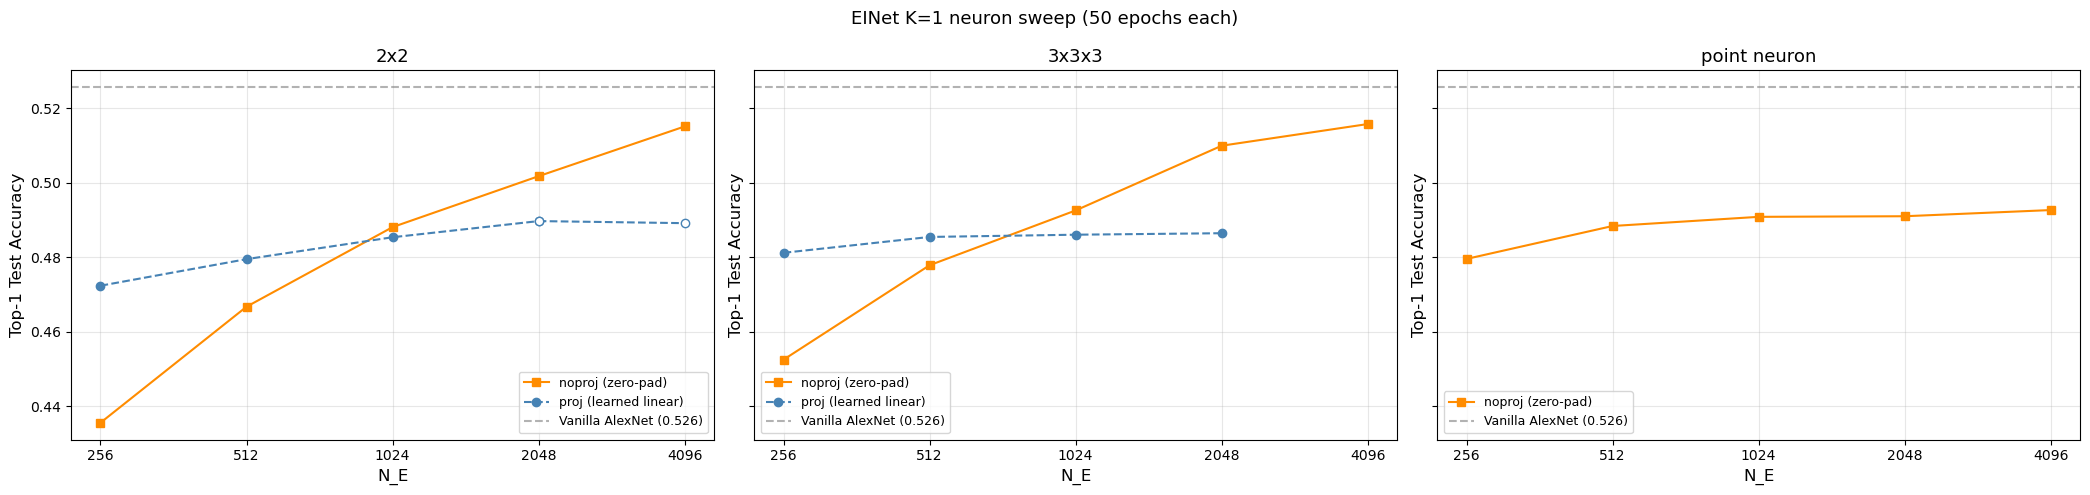

In [1]:
import json, glob, os
import matplotlib.pyplot as plt

# Results are split across two locations:
# - holylfs06: original sweeps (Apr 9-16)
# - home:      new runs (Apr 23+) that wrote before results_dir was updated
outputs_dirs = [
    "/n/holylfs06/LABS/kempner_project_b/Lab/dendritic/adivm/dendritic-modeling/outputs",
    "/n/home13/adithyavm/dendritic-modeling/outputs",
]

def load_acc(pattern, exclude=None):
    dirs = []
    for outputs in outputs_dirs:
        found = sorted(glob.glob(f"{outputs}/{pattern}"))
        if exclude:
            found = [d for d in found if exclude not in os.path.basename(d)]
        dirs.extend(found)
    dirs = sorted(dirs)
    for d in reversed(dirs):
        f = f"{d}/performance/final.json"
        if os.path.exists(f):
            return json.load(open(f))["accuracy"]["test"]
    return None

vanilla    = json.load(open(f"{outputs_dirs[0]}/alexnet_baseline/performance.json"))["test"]["top1_accuracy"]
einet_4096 = load_acc("alexnet_k1_einet_ddp_*")

ns       = [256, 512, 1024, 2048, 4096]
ns_proj  = [256, 512, 1024, 2048]

noproj_2x2   = [load_acc(f"alexnet_k1_ne{n}_noproj_ddp_*")        for n in ns]
noproj_3x3x3 = [load_acc(f"alexnet_k1_ne{n}_3x3x3_noproj_ddp_*") for n in ns]
proj_2x2     = [load_acc(f"alexnet_k1_ne{n}_ddp_*",       exclude="noproj") for n in ns_proj]
proj_3x3x3   = [load_acc(f"alexnet_k1_ne{n}_3x3x3_ddp_*", exclude="noproj") for n in ns_proj]
proj_4096_2x2 = load_acc("alexnet_k1_ne4096_proj_ddp_*")
noproj_point  = [load_acc(f"alexnet_k1_ne{n}_point_noproj_ddp_*") for n in ns]

fig, axes = plt.subplots(1, 3, figsize=(21, 5), sharey=True)

for ax, title, noproj, proj, p4096 in [
    (axes[0], "2x2",         noproj_2x2,   proj_2x2,   proj_4096_2x2),
    (axes[1], "3x3x3",       noproj_3x3x3, proj_3x3x3, None),
    (axes[2], "point neuron", noproj_point, None,        None),
]:
    ax.plot(ns,      noproj, marker='s', color='darkorange', label='noproj (zero-pad)')
    if proj is not None:
        ax.plot(ns_proj, proj,   marker='o', color='steelblue', linestyle='--', label='proj (learned linear)')
    if p4096 is not None:
        ax.plot([2048, 4096], [proj[-1], p4096], marker='o', color='steelblue',
                linestyle='--', markerfacecolor='white')

    ax.axhline(vanilla, color='gray', linestyle='--', alpha=0.6, label=f'Vanilla AlexNet ({vanilla:.3f})')

    ax.set_xscale('log', base=2)
    ax.set_xticks(ns)
    ax.set_xticklabels(ns)
    ax.set_xlabel('N_E', fontsize=12)
    ax.set_ylabel('Top-1 Test Accuracy', fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

fig.suptitle('EINet K=1 neuron sweep (50 epochs each)', fontsize=13)
plt.tight_layout()
plt.savefig('sweep_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [3]:
from tabulate import tabulate

rows = [
    [256,  noproj_2x2[0], noproj_3x3x3[0], proj_2x2[0], proj_3x3x3[0], noproj_point[0]],
    [512,  noproj_2x2[1], noproj_3x3x3[1], proj_2x2[1], proj_3x3x3[1], noproj_point[1]],
    [1024, noproj_2x2[2], noproj_3x3x3[2], proj_2x2[2], proj_3x3x3[2], noproj_point[2]],
    [2048, noproj_2x2[3], noproj_3x3x3[3], proj_2x2[3], proj_3x3x3[3], noproj_point[3]],
    [4096, noproj_2x2[4], noproj_3x3x3[4], proj_4096_2x2, None,         noproj_point[4]],
    ["AlexNet", vanilla,  None,             None,          None,         None],
]

fmt = lambda v: f"{v:.4f}" if v is not None else "pending"
rows = [[r[0]] + [fmt(v) for v in r[1:]] for r in rows]

print(tabulate(rows, headers=["N_E", "noproj 2x2", "noproj 3x3x3", "proj 2x2", "proj 3x3x3", "point"], tablefmt="pretty"))


+---------+------------+--------------+----------+------------+---------+
|   N_E   | noproj 2x2 | noproj 3x3x3 | proj 2x2 | proj 3x3x3 |  point  |
+---------+------------+--------------+----------+------------+---------+
|   256   |   0.4355   |    0.4525    |  0.4723  |   0.4812   | 0.4795  |
|   512   |   0.4667   |    0.4778    |  0.4795  |   0.4854   | 0.4884  |
|  1024   |   0.4881   |    0.4926    |  0.4854  |   0.4860   | 0.4908  |
|  2048   |   0.5018   |    0.5099    |  0.4897  |   0.4864   | 0.4910  |
|  4096   |   0.5151   |    0.5158    |  0.4891  |  pending   | 0.4927  |
| AlexNet |   0.5257   |   pending    | pending  |  pending   | pending |
+---------+------------+--------------+----------+------------+---------+
